# 01 - Data exploration: audit, cleaning, matching and EDA

PM2.5 forecasting, Group 1. Section numbers (for example **§5.1**) refer to the project brief.
The code lives in `src/` (`preprocessing.py`, `eda.py`); this notebook calls it and comments the results.
`scripts/run_eda.py` runs the same steps and writes `results/Exploratory_Data.csv`.

| Section | Content | Part |
| --- | --- | --- |
| §3.1 Mandatory dataset audit | source, license, units, size, dates, coverage, missing, duplicates, distributions, independence, leakage, timestamps/IDs | 1 |
| §5.1 Cleaning | remove invalid PM2.5, duplicates | 2 |
| §5.3.4 Matching | stations to GEE IDs by date and nearest lat/lon (0.25°) | 3 |
| §5.1 Data exploration | summaries, plots, outliers, correlations, relationships, target distribution | 4 |

In [1]:
import sys
sys.path.insert(0, "..")          # project root, so that `src` can be imported
%matplotlib inline
from src import preprocessing as prep, eda, timeseries as ts
eda_rows, temporal_rows = [], []  # results are written by scripts/run_eda.py; here they are only displayed

# Part 1. §3.1 Dataset audit

## 1.1 Source, license, units

In [2]:
prep.dataset_description()

,item,value
0,Dataset,Air Quality - Mediterranean Basin (2016-2026)
1,Source,https://www.kaggle.com/datasets/sarahameziane/...
2,License,Other (specified in description) on Kaggle; bu...
3,Files used,"pm25.csv (ground stations), gee_features_daily..."
4,Target,"pm25: daily surface PM2.5 concentration, ug/m3"
5,Task,Regression / forecasting (not classification)


,variable,meaning,unit,origin
0,pm25,Daily PM2.5 at a ground station (TARGET),ug/m3,ground station
1,AOD,Aerosol optical depth (light blocked by airbor...,unitless,satellite
2,NO2,Nitrogen dioxide column,mol/m2 (inferred from magnitude),Sentinel-5P
3,CO,Carbon monoxide column,mol/m2 (inferred from magnitude),Sentinel-5P
4,O3,Ozone column,mol/m2 (inferred from magnitude),Sentinel-5P
5,temperature_celsius,Air temperature,degrees C,reanalysis
6,pressure_mb,Surface pressure,mb (= hPa),reanalysis
7,wind_u,"Wind component, east-west",m/s (inferred),reanalysis
8,wind_v,"Wind component, north-south",m/s (inferred),reanalysis
9,sensor_name / lat / lon,"Station name and coordinates (group labels, NO...",-,ground station


Units marked *inferred* are deduced from the size of the values (for example NO2 is about 0.0001).

## 1.2 Rows, columns, date range, spatial coverage

In [3]:
P, G = prep.load_raw()
prep.audit_size_and_coverage(P, G, eda_rows)

,rows,columns,first_date,last_date,distinct_dates,distinct_sensor_name,lat_min,lat_max,lon_min,lon_max,distinct_id
pm25.csv,88041,5,2016-11-21,2026-04-16,3131,125,34.29,43.689,-5.663,9.446,NaN
gee_features_daily.csv,164208,13,2016-11-21,2026-04-06,2393,NaN,36.133,43.53,-5.663,9.136,100


## 1.3 Missing values and duplicates

In [4]:
prep.audit_missing_and_duplicates(P, G, eda_rows)

,pm25.csv missing %,gee_features_daily.csv missing %
CO,NaN,11.94
NO2,NaN,11.94
O3,NaN,12.13


,duplicates
pm25.csv: full rows,0
pm25.csv: date + station,1558
pm25.csv: date + lat + lon,0
pm25.csv: date + lat + lon + station,0
gee_features_daily.csv: full rows,0
gee_features_daily.csv: date + id,0
gee_features_daily.csv: date + lat + lon,0


`date + station` has many repeats in `pm25.csv` but `date + lat + lon + station` has none: the same name is attached to **different coordinates** (see 1.7).

## 1.4 Target and predictor distributions (raw)

In [5]:
prep.audit_distributions(P, G)

count    88041.00
mean         8.00
std         40.80
min       -999.00
25%          4.60
50%          7.95
75%         12.39
max       1000.00
Name: pm25, dtype: float64

PM2.5 <= 0   : 2093 -> {0.0: 1428, -1.0: 324, -999.0: 96}
PM2.5 >= 500 : 19 -> {1000.0: 3, 998.0: 3, 916.05: 2}


,count,mean,std,min,25%,50%,75%,max
temperature_celsius,164208.0,18.01704,6.52662,-1.27905,12.63491,18.13682,23.71099,35.06272
pressure_mb,164208.0,995.02278,16.68051,928.24849,988.70897,998.62594,1006.29250,1033.66218
wind_u,164208.0,0.33891,2.40292,-11.09872,-0.89984,0.23908,1.50981,9.66165
wind_v,164208.0,-0.21863,1.49767,-10.86005,-0.77902,0.03336,0.67452,8.48638
NO2,144605.0,0.00010,0.00003,0.00002,0.00008,0.00009,0.00011,0.00048
CO,144605.0,0.03169,0.00391,0.01306,0.02907,0.03151,0.03405,0.09761
O3,144294.0,0.14315,0.01442,0.10351,0.13368,0.14027,0.15043,0.23125
AOD,164208.0,0.15039,0.12454,0.00000,0.08000,0.12867,0.19600,8.04800


`-999` and `1000` are not concentrations: they are codes for "no valid reading" (sentinel values), removed in Part 2 before the exploration.

## 1.5 Independence and grouping of observations

In [6]:
prep.audit_independence(P, eda_rows)

share of raw PM2.5 variance explained by station: 11.7%
share of log1p PM2.5 variance explained by station: 22.5%


Spearman correlation between a day and the previous day, same station: 0.75
Observations per station: {'count': 118.0, 'mean': 728.0, 'std': 425.0, 'min': 15.0, '25%': 360.0, '50%': 761.0, '75%': 1077.0, 'max': 2079.0}


**Consequence.** Observations are grouped (by station) and ordered (by time), so they are **not independent**. A random shuffle would put neighbouring days and sister stations on both sides of the split and look too optimistic. Hence temporal CV is mandatory, spatial CV is grouped by station, and random CV is diagnostic only.

## 1.6 No input derived from the target

In [7]:
prep.audit_target_leakage(G)

'pm25' column in the GEE file? False
Inputs available: ['temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v', 'NO2', 'CO', 'O3', 'AOD']
Features built later from the target: only pm25_lag1 and pm25_roll7_mean (strictly PAST days, see features.py).


The GEE variables come from satellites and reanalysis, independent of the stations' PM2.5 readings. The only target-derived features use **past days only** and are allowed only for forecasts at least one day ahead. Station name and coordinates are group labels, never predictors.

## 1.7 Timestamps, station identifiers and coordinates

In [8]:
P, spatial_cv_ok = prep.audit_timestamps_and_ids(P, G, eda_rows)

unparseable dates: 0 (pm25) 0 (GEE)
GEE datetime_utc equals date everywhere: True
Coordinates plausible for the Mediterranean (lat 30-46, lon -10-20): True
GEE ids with more than one coordinate: 0 of 100

station names with more than one coordinate: 7 of 125


,n_coords,rows,max_spread_deg
sensor_name,,,
Barcelona,3,2079,0.0773
SAN BASILIO,2,860,0.0018
LA ALJORRA,2,761,0.0016
MOMPEAN,2,1373,0.0016
Viladecavalls,2,75,0.0002
MOLINA DE SEGURA,2,732,0.0001
SSOO,2,1232,0.0000


station names: 125 -> station_ids: 127
largest coordinate spread inside one station_id (deg): 0.0013
['Barcelona #1', 'Barcelona #2', 'Barcelona #3']

Decision gate (section 3.1): reliable station IDs and coordinates -> spatial CV is allowed


**Finding.** Seven station names carry several coordinates. Six only shift by 0.002° or less (the same physical station). But **"Barcelona" is three different stations**, 0.04° to 0.08° apart, reporting on the same dates under one name. Grouping by `sensor_name` would mix them.

**Fix.** Within each name, coordinates closer than 0.01° are merged and the rest split, which gives a reliable `station_id` and allows spatial CV.

# Part 2. §5.1 Remove invalid PM2.5 and merge duplicates

Rows with missing PM2.5 or sentinel values (PM2.5 <= 0 or >= 500) are removed before EDA and splitting. Several readings of one station on one date are merged by averaging.

In [9]:
P = prep.remove_invalid(P, eda_rows)

,count
pm25_rows_raw,88041
removed_pm25_missing,0
removed_pm25_le_0,2093
removed_pm25_ge_500,19
pm25_rows_after_invalid_removal,85929


,duplicates
full rows,0
date + station_id,567
date + lat + lon,0
date + lat + lon + station_id,0


,date,station_id,latitude,longitude,pm25
58617,2024-08-30,LA ALJORRA,37.692500,-1.065900,9.7000
58618,2024-08-30,LA ALJORRA,37.693611,-1.064722,10.9775
58622,2024-08-30,MOLINA DE SEGURA,38.057300,-1.204700,11.6650
58623,2024-08-30,MOLINA DE SEGURA,38.057373,-1.204813,10.5300
58615,2024-08-30,MOMPEAN,37.601800,-0.976200,13.1300
58616,2024-08-30,MOMPEAN,37.603056,-0.975278,14.6350


unique station-days: 85362 | stations: 120


# Part 3. §5.3.4 Match stations to GEE IDs

1. Each `station_id` gets **one** GEE ID: the nearest GEE grid point.
2. If that point is farther than **0.25°**, the station is dropped.
3. Join on **date + GEE ID**; a station-day without a GEE record on that date is dropped.

stations matched within 0.25 deg: 107 of 120
exact coordinate matches (distance 0): 91

unmatched stations (nearest GEE point too far):


,station_id,lat,lon,dist_deg,n_readings
12,Algiers,36.756,3.039,3.928,550
16,BASTIA GIRAUD,42.698,9.446,3.451,831
17,BASTIA MONTESORO,42.671,9.435,3.424,753
28,CANNES BROUSSAILLES,43.558,7.006,1.542,794
36,CIUTADELLA DE MENORCA,40.011,3.858,2.163,652
45,ES1828A,40.009,3.856,2.162,31
46,ESTEREL,43.438,6.768,1.301,803
47,ETAP,35.310,-2.957,1.614,672
56,FR24009,43.563,7.007,1.544,835
76,Malek,34.290,8.762,4.958,74


,count
station_days_before_matching,85362
lost_station_too_far_from_any_GEE_point,8061
lost_no_GEE_record_for_that_date,30389
station_days_matched,46912
stations_matched,107
gee_ids_used,91


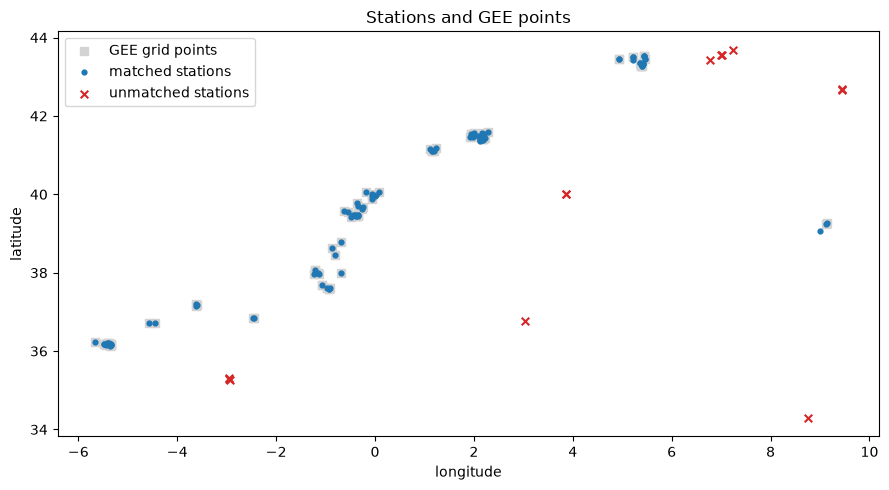

In [10]:
df = prep.match_gee(P, G, eda_rows)
df = eda.add_derived_columns(df)      # wind speed, year, month, season

# Part 4. §5.1 Data exploration

## 4.1 Describe the dataset

In [11]:
eda.describe(df)

rows 46912 | stations 107 | GEE points 91 | 2016-11-25 -> 2026-04-06
lat 36.13..43.53 | lon -5.66..9.14
Target: pm25 (ug/m3, continuous). Predictors: ['AOD', 'NO2', 'CO', 'O3', 'temperature_celsius', 'pressure_mb', 'wind_u', 'wind_v']


## 4.2 Numerical summaries and categorical counts

In [12]:
eda.numerical_summary(df, eda_rows)

,count,mean,std,min,25%,50%,75%,max,skewness,kurtosis,missing_pct
pm25,46912.0,9.40595,9.39116,0.00667,4.68181,7.83000,12.00000,484.98150,17.43461,656.76379,0.00000
AOD,46912.0,0.14764,0.10519,0.00000,0.07900,0.12750,0.19333,5.47500,7.27102,229.46885,0.00000
NO2,44505.0,0.00009,0.00003,0.00002,0.00008,0.00009,0.00010,0.00048,2.08379,8.61441,5.13088
CO,44505.0,0.03172,0.00395,0.01306,0.02916,0.03154,0.03398,0.09761,1.45962,13.40361,5.13088
O3,44464.0,0.14417,0.01495,0.10390,0.13432,0.14098,0.15186,0.22932,1.16344,2.23539,5.21828
temperature_celsius,46912.0,18.14692,6.43749,-1.27905,12.78628,18.31082,23.71302,34.86583,-0.10214,-0.97075,0.00000
pressure_mb,46912.0,994.11286,16.54160,930.31707,988.21171,997.47579,1005.25832,1033.66218,-1.09457,0.92043,0.00000
wind_u,46912.0,0.39591,2.48182,-11.09872,-0.91706,0.24697,1.72155,9.66165,-0.17306,1.08241,0.00000
wind_v,46912.0,-0.23424,1.48287,-10.86005,-0.80184,0.02661,0.67549,8.48638,-1.35265,4.03117,0.00000


year,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
rows,111,2116,252,1772,3251,4938,5117,6022,11251,10080,2002


stations: median 458 rows | min 4 | max 1042


## 4.3 Visualisations: PM2.5, AOD, NO2, CO, O3, temperature, pressure, wind

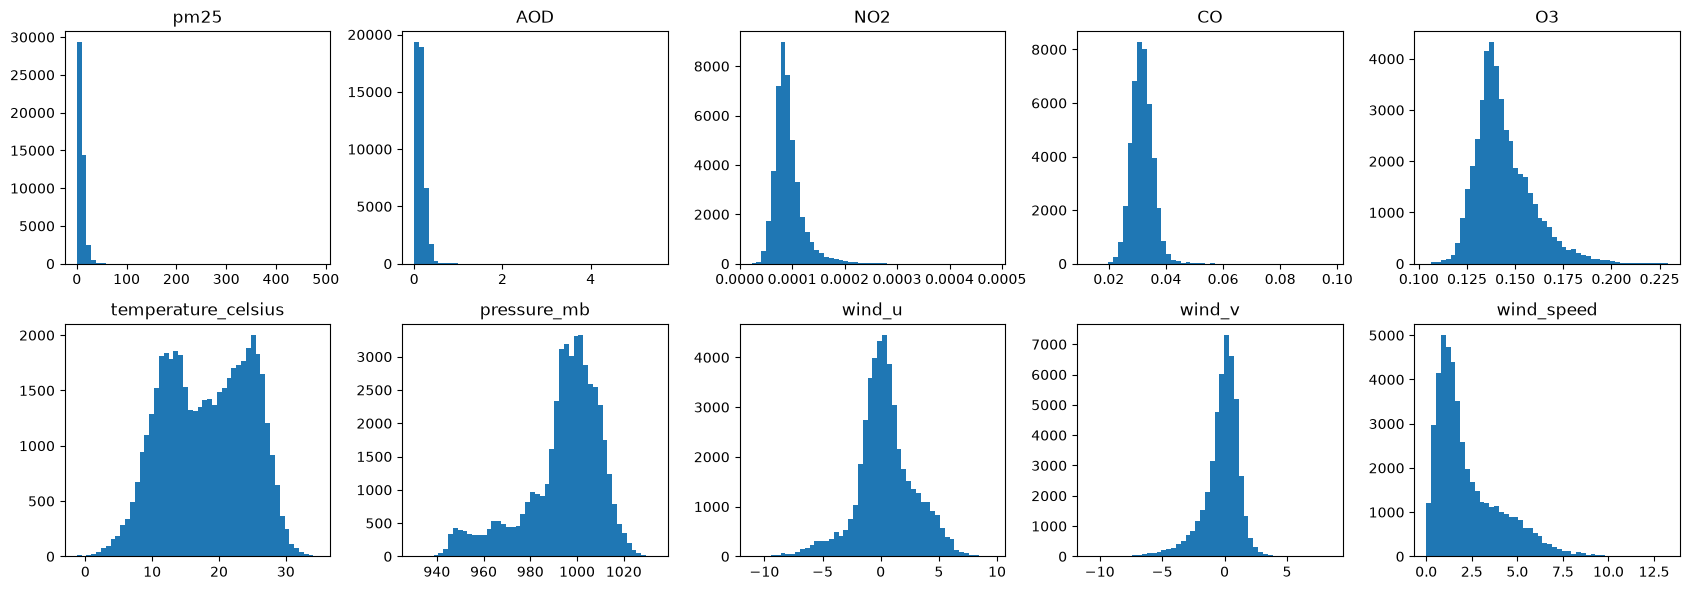

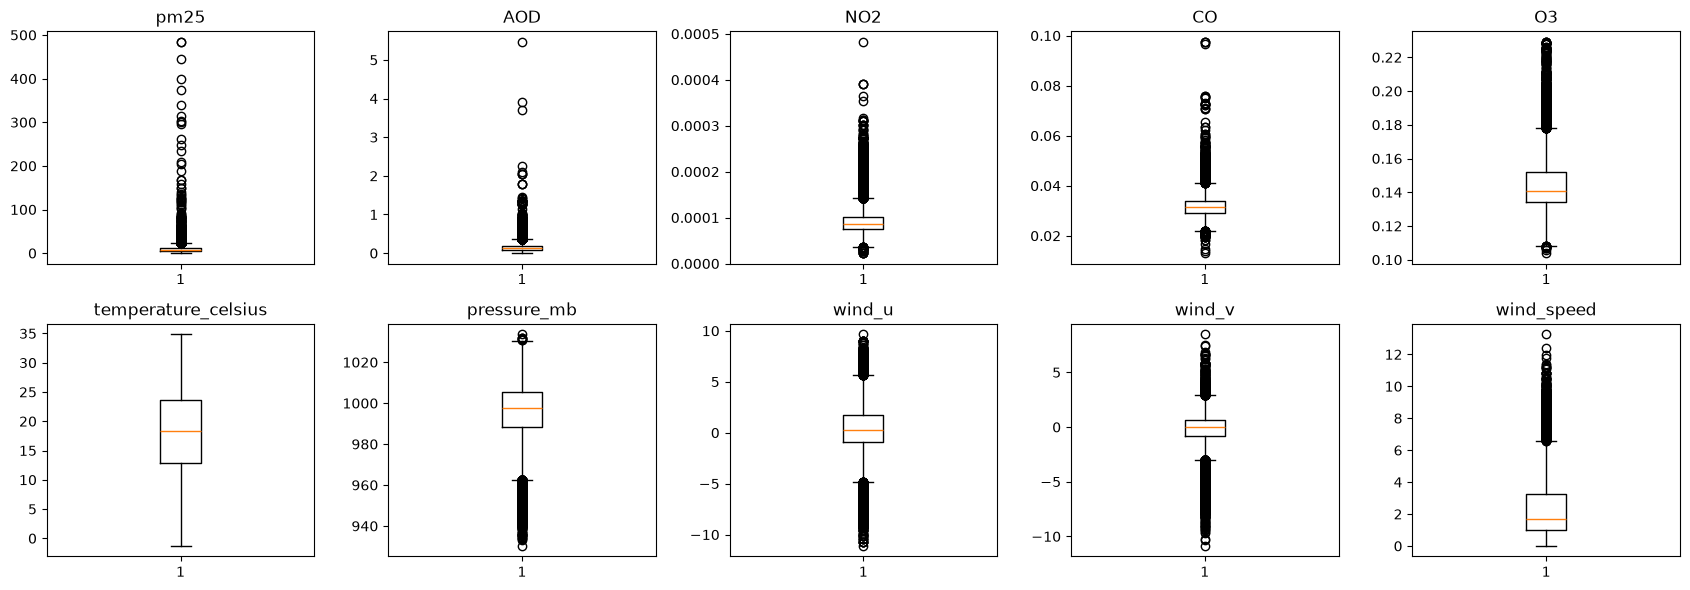

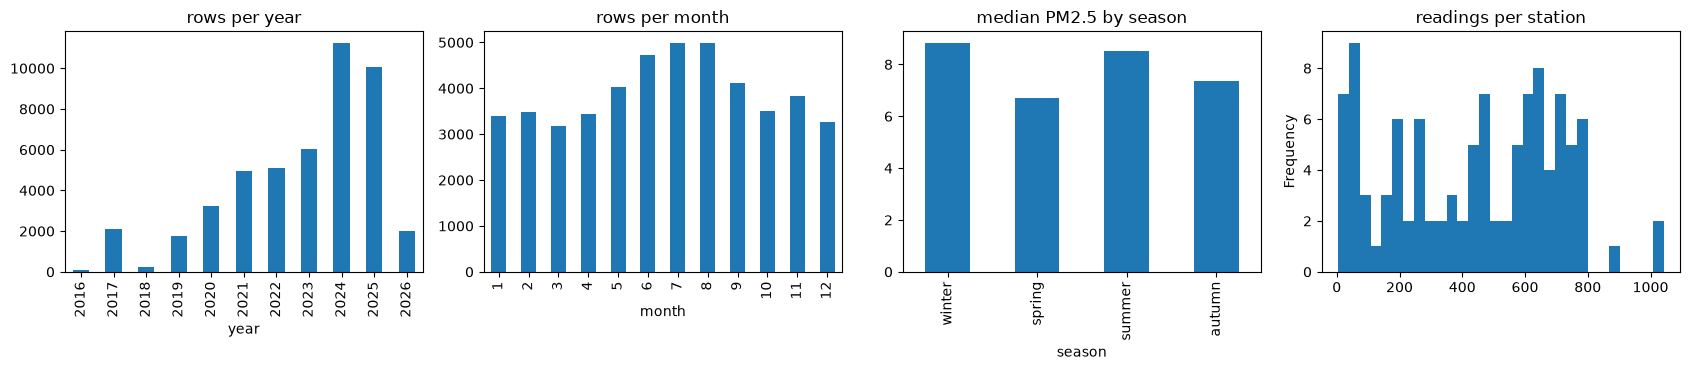

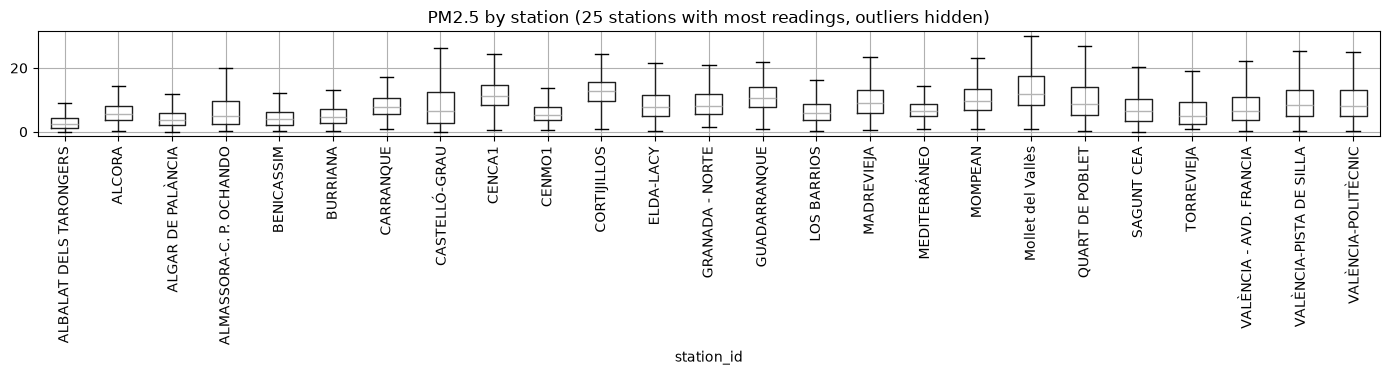

In [13]:
eda.distribution_plots(df)

## 4.4 Missingness and potential outliers (IQR, z-scores, Isolation Forest)

In [14]:
eda.outliers(df, eda_rows)

Missing % per variable: {'NO2': 5.13, 'CO': 5.13, 'O3': 5.22}


,iqr_low,iqr_high,n_iqr_outliers,pct_iqr_outliers,n_abs_z_gt_3
variable,,,,,
pm25,-6.2955,22.9773,1915,4.0821,326
AOD,-0.0925,0.3648,1259,2.6837,337
NO2,0.0000,0.0001,2343,5.2646,850
CO,0.0219,0.0412,688,1.5459,333
O3,0.1080,0.1782,1484,3.3375,549
temperature_celsius,-3.6038,40.1031,0,0.0000,4
pressure_mb,962.6418,1030.8282,3316,7.0686,177
wind_u,-4.8750,5.6795,2367,5.0456,343
wind_v,-3.0178,2.8915,2706,5.7682,910


Isolation Forest flags 468 rows (1.0%)
median PM2.5 of flagged rows: 5.32 | of the others: 7.84
Highest PM2.5 values (candidate episodes or errors):


,date,station_id,pm25,AOD,wind_speed
12751,2024-09-04,CENCA1,484.9815,0.257500,1.765724
25875,2021-11-22,LOS BARRIOS,483.8750,0.167500,5.329163
24041,2021-11-02,HOSTELERÍA,445.0625,0.512000,3.778308
25912,2022-01-19,LOS BARRIOS,399.4000,0.164000,5.366519
24086,2022-01-07,HOSTELERÍA,373.0000,0.054000,0.751909
23145,2022-02-14,GUADARRANQUE,338.8000,0.124250,3.968598
8312,2021-11-07,CAMPAMENTO,315.0000,0.047500,0.194813
2028,2020-04-04,ALCORA,303.5000,0.172333,0.872195


Outliers are **inspected, not removed**: extreme but plausible PM2.5 values are kept and only documented errors (the sentinel codes) were removed. The treatment decision is tested on held-out data in `scripts/run_preprocessing.py` (§5.3.3).

## 4.5 Correlations: Pearson, Spearman, |r| > 0.9, VIF, PCA

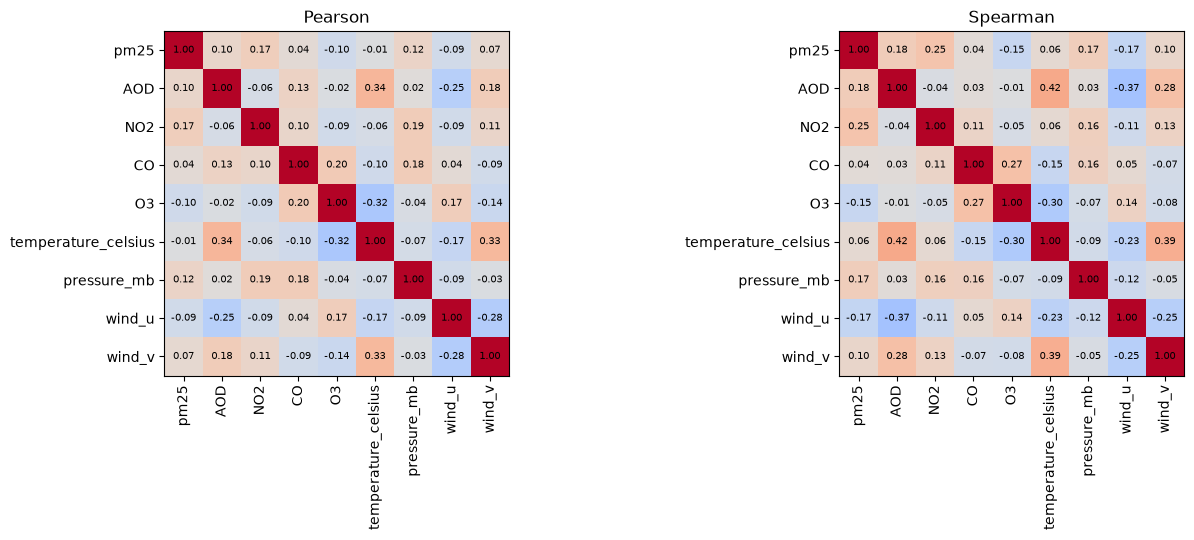

,pearson,spearman
wind_u,-0.088,-0.173
O3,-0.101,-0.153
CO,0.043,0.038
temperature_celsius,-0.011,0.062
wind_v,0.065,0.096
pressure_mb,0.116,0.172
AOD,0.095,0.181
NO2,0.167,0.249


Predictor pairs with |r| > 0.9 (Pearson or Spearman): none


,AOD,NO2,CO,O3,temperature_celsius,pressure_mb,wind_u,wind_v
VIF,1.24,1.08,1.12,1.19,1.38,1.08,1.18,1.21


PCA cumulative explained variance: [0.24 0.41 0.56 0.67 0.77 0.86 0.94 1.  ]


In [15]:
eda.correlations(df, eda_rows)

**How to read it.** VIF near 1 means a predictor is not explained by the others (above 5 to 10 would signal multicollinearity). All VIFs are below 1.5 and PCA needs about six of the eight components for 86% of the variance, so there is no multicollinearity problem. Correlations with PM2.5 are weak for every single variable, which warns that the task is hard; non-linear models and lagged features may still find structure. *(t-SNE / UMAP are optional and are not proof of predictive value; skipped.)*

## 4.6 PM2.5 versus predictors: seasonal, station and meteorological differences

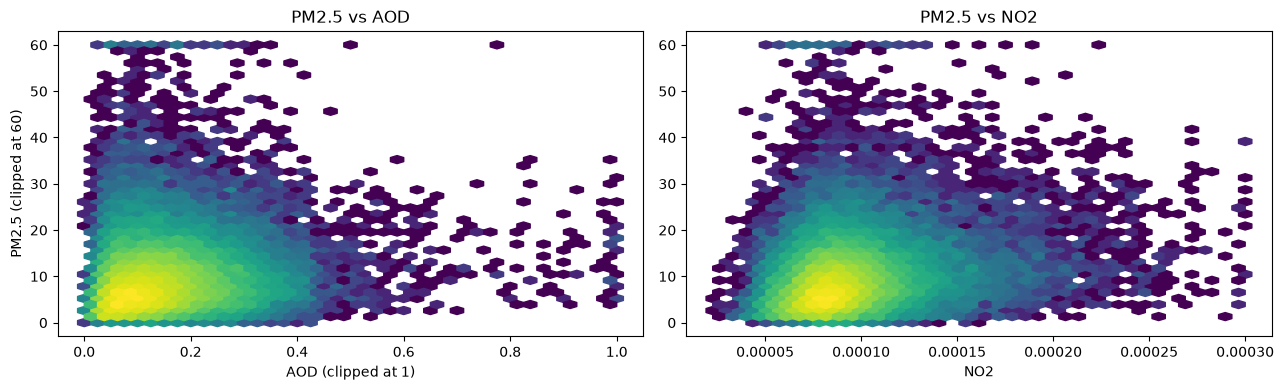

Spearman(PM2.5, AOD) by season:


season,winter,spring,summer,autumn
rho,0.241,0.162,0.222,0.216


Spearman(PM2.5, AOD) per station (90 stations with >= 100 rows): median 0.21, share positive 96%, range -0.18 to 0.55


,low,mid,high
wind_speed,0.124,0.086,0.297
temperature_celsius,0.185,0.174,0.208
pressure_mb,0.188,0.204,0.134


In [16]:
eda.pm25_vs_predictors(df, eda_rows)

The AOD to PM2.5 relationship **changes with the season, the station and the weather**, so a single global coefficient would be crude. This supports calendar features, meteorological variables and non-linear models.

## 4.7 The target distribution

,mean,median,std,skewness,kurtosis,share_gt_25_pct,share_gt_50_pct,max
PM2.5,9.406,7.83,9.391,17.435,656.764,2.972,0.262,484.982


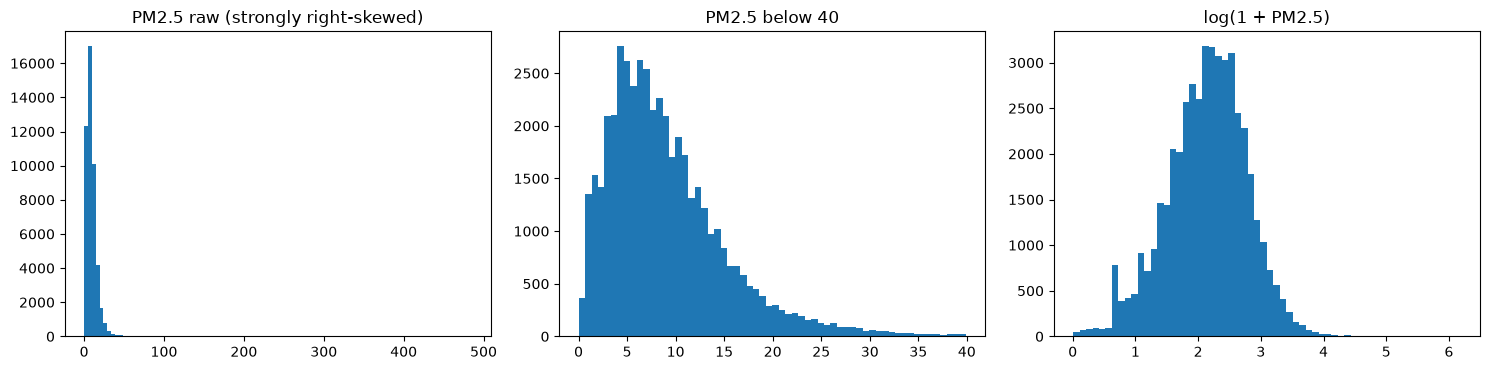

month,1,2,3,4,5,6,7,8,9,10,11,12
median,8.21,9.20,7.32,6.25,6.61,7.80,8.18,9.50,6.73,7.76,7.95,9.00
mean,10.42,11.28,9.56,7.51,7.54,9.14,9.01,10.51,7.93,9.00,10.05,11.36
share_gt25,5.01,6.73,4.25,1.22,0.72,2.18,1.16,2.36,1.29,2.29,3.32,7.50


In [17]:
eda.target_distribution(df, eda_rows)

**What this means for the error metrics.**
- Most days are clean (the median is far below the mean) and a few days are extreme; the mean and standard deviation are dominated by those rare days.
- **RMSE squares errors**, so a handful of extreme days can dominate it. **MAE** is closer to the typical error. Report both.
- Few days exceed 25 µg/m³ and even fewer exceed 50, so a model can score well overall while missing nearly every pollution episode: evaluate **extreme-event errors separately**.
- The `log1p` target is far more symmetric and will be tested in the ablation, always evaluated back on the µg/m³ scale.